# 03 · Robustness study

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from visionguard.common.config import get_settings
from visionguard.storage.database import Database

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
rob = Database(get_settings().db_path).query_df("SELECT * FROM robustness")
rob.pivot_table(index=["corruption", "level"], columns="model", values="macro_f1").round(3)

model                    baseline  improved  robust
corruption       level                             
blur_sigma        0.000     0.651     0.850   0.825
                  0.500     0.595     0.698   0.744
                  1.000     0.384     0.072   0.478
                  1.500     0.293     0.051   0.100
                  2.000     0.200     0.051   0.051
                  3.000     0.120     0.051   0.051
brightness       -0.300     0.588     0.785   0.772
                 -0.200     0.651     0.850   0.825
                 -0.100     0.651     0.850   0.825
                  0.000     0.651     0.850   0.825
                  0.100     0.651     0.850   0.825
                  0.200     0.651     0.850   0.825
                  0.300     0.596     0.789   0.790
noise_std         0.000     0.651     0.850   0.825
                  0.020     0.673     0.782   0.834
                  0.040     0.508     0.208   0.638
                  0.060     0.334     0.051   0.529
                  0.080     0.165     0.051   0.391
                  0.120     0.131     0.051   0.215
resolution_scale  0.250     0.214     0.051   0.051
                  0.375     0.287     0.051   0.077
                  0.500     0.351     0.051   0.166
                  0.750     0.411     0.203   0.573
                  1.000     0.651     0.850   0.825

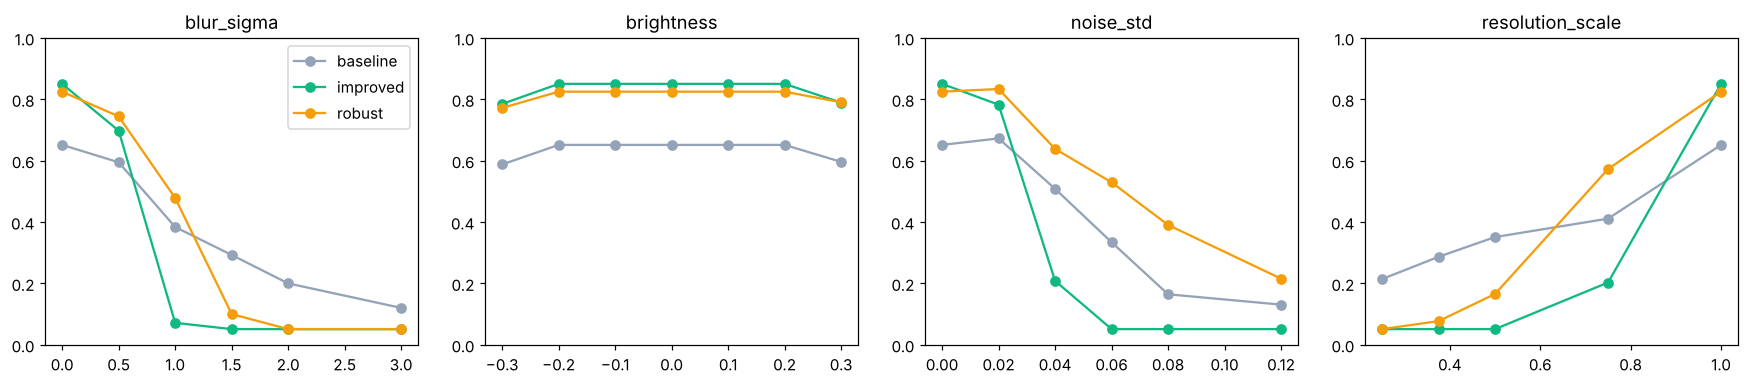

In [2]:
colors = {"baseline": "#94a3b8", "improved": "#10b981", "robust": "#f59e0b"}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (kind, g) in zip(axes, rob.groupby("corruption")):
    for mname, gg in g.groupby("model"):
        ax.plot(gg.level, gg.macro_f1, "o-", label=mname, color=colors[mname])
    ax.set(title=kind, ylim=(0, 1))
axes[0].legend()
plt.tight_layout()

**Findings.**
* Brightness is handled well by every model because features are computed on illumination-normalised images.
* Texture features are **brittle** to blur, noise and down-sampling: the improved model collapses to a
  single class at blur σ ≥ 1 or noise σ ≥ 0.06.
* Corruption-aware training trades ~2–3 points of clean macro-F1 for large gains under moderate shift
  (e.g. noise σ = 0.04). Severe levels beyond the training range still fail — a CNN with stronger
  augmentation is the next experiment.